# Coastal Weather Comparison: Karachi vs. Mumbai

A standalone data engineering and exploratory analysis project comparing winter coastal weather dynamics between **Karachi, Pakistan** and **Mumbai, India**.

### Pipeline Overview
1. **Data Acquisition:** Scrape past 14 days of hourly historic observations (`#wt-his`) and 14-day daily forecasts (`#wt-ext`) into `dataset/`.
2. **Data Cleaning & Integration:** Standardize timestamps, coerce numeric metrics safely, deduplicate, and save `dataset/coastal_weather_cleaned.csv`.
3. **Exploratory Analysis & Visualizations:** Generate comparative summary statistics and save publication charts to `visualizations/`.
4. **Analytical Insights:** Quantify diurnal temperature variation, morning humidity, afternoon pressure, and precipitation differences.

## 1. Environment Setup

In [1]:
# pip install requests beautifulsoup4 pandas numpy matplotlib seaborn

import os
import random
import re
import time
import warnings
from datetime import datetime, timedelta

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from bs4 import BeautifulSoup, Tag
from IPython.display import Markdown, display

os.makedirs('dataset', exist_ok=True)
os.makedirs('visualizations', exist_ok=True)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## 2. Data Acquisition (Web Scraping)

Scrape historical hourly observations and 14-day forecasts from TimeAndDate for Karachi and Mumbai, saving the raw outputs to `dataset/karachi_raw.csv` and `dataset/mumbai_raw.csv`.  
*(Note: Set `RUN_SCRAPER = True` below to re-fetch live data; otherwise, the pipeline uses the existing CSV files in `dataset/`.)*

In [2]:
RUN_SCRAPER = False

TARGETS = {
    'Karachi': ('pakistan', 'dataset/karachi_raw.csv'),
    'Mumbai': ('india', 'dataset/mumbai_raw.csv'),
}

HEADERS = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36'
}


def scrape_weather_data(city: str, country: str, filename: str) -> None:
    print(f"Starting scraping for {city}...")
    weather_data = []
    current_date = datetime.now()

    # Phase 1: Past 14 days (hourly historic records)
    for i in range(14, 0, -1):
        target_date = current_date - timedelta(days=i)
        year, month, day = target_date.year, target_date.month, target_date.day
        url = f"https://www.timeanddate.com/weather/{country}/{city.lower()}/historic?month={month}&day={day}&year={year}"

        try:
            response = requests.get(url, headers=HEADERS, timeout=15)
            if response.status_code != 200:
                print(f"Failed ({response.status_code}) for {year}-{month:02d}-{day:02d}")
                continue

            soup = BeautifulSoup(response.content, 'html.parser')
            table = soup.find('table', {'id': 'wt-his'})
            tbody = table.find('tbody') if isinstance(table, Tag) else None
            if not isinstance(tbody, Tag):
                continue

            for row in tbody.find_all('tr'):
                row_html = str(row)

                ts_match = re.search(r'<th[^>]*>(\d{1,2}:\d{2})', row_html)
                timestamp = ts_match.group(1) if ts_match else '00:00'

                temp_match = re.search(r'(\d+)\s*°C', row_html)
                temperature = temp_match.group(1) if temp_match else np.nan

                weather_match = re.search(r'<td class="small"[^>]*>(.*?)</td>', row_html)
                weather = weather_match.group(1).rstrip('.') if weather_match else 'N/A'

                wind_match = re.search(r'(\d+|No wind)(?=\s*km/h|<)', row_html, re.IGNORECASE)
                wind_speed = wind_match.group(1) if wind_match else '0'
                if str(wind_speed).lower() == 'no wind':
                    wind_speed = '0'

                dir_match = re.search(r'title="([^"]+)"[^>]*>([^<]+)<', row_html)
                wind_dir = dir_match.group(1) if dir_match else 'N/A'

                hum_match = re.search(r'(\d+)%', row_html)
                humidity = hum_match.group(1) if hum_match else np.nan

                bar_match = re.search(r'(\d+)\s*mbar', row_html)
                barometer = bar_match.group(1) if bar_match else np.nan

                vis_match = re.search(r'(\d+)\s*km', row_html)
                visibility = vis_match.group(1) if vis_match else np.nan

                weather_data.append({
                    'Date & Time': f"{year}-{month:02d}-{day:02d} {timestamp}",
                    'City': city,
                    'Temperature (°C)': temperature,
                    'Weather': weather,
                    'Wind Speed (km/h)': wind_speed,
                    'Wind Direction': wind_dir,
                    'Humidity (%)': humidity,
                    'Barometer (mbar)': barometer,
                    'Visibility (km)': visibility,
                    'Data Source': 'Historic',
                })

            time.sleep(random.uniform(0.5, 1.5))
        except (requests.RequestException, AttributeError, ValueError) as exc:
            print(f"Error scraping {city} {year}-{month:02d}-{day:02d}: {exc}")

    # Phase 2: Next 14 days (daily forecast summary)
    forecast_url = f"https://www.timeanddate.com/weather/{country}/{city.lower()}/ext"
    try:
        response = requests.get(forecast_url, headers=HEADERS, timeout=15)
        soup = BeautifulSoup(response.content, 'html.parser')
        forecast_table = soup.find('table', {'id': 'wt-ext'})
        forecast_tbody = forecast_table.find('tbody') if isinstance(forecast_table, Tag) else None

        if isinstance(forecast_tbody, Tag):
            for i, row in enumerate(forecast_tbody.find_all('tr')):
                if i >= 14:
                    break
                row_html = str(row)
                future_date = current_date + timedelta(days=i)
                date_str = f"{future_date.year}-{future_date.month:02d}-{future_date.day:02d} 12:00"

                temp_match = re.search(r'(\d+)\s*/\s*\d+\s*°C', row_html)
                temperature = temp_match.group(1) if temp_match else np.nan

                weather_match = re.search(r'<td class="small"[^>]*>(.*?)</td>', row_html)
                weather = weather_match.group(1).rstrip('.') if weather_match else 'N/A'

                wind_match = re.search(r'(\d+)\s*km/h', row_html)
                wind_speed = wind_match.group(1) if wind_match else '0'

                hum_match = re.search(r'(\d+)%', row_html)
                humidity = hum_match.group(1) if hum_match else np.nan

                dir_match = re.search(r'title="([^"]+)"[^>]*>([^<]+)<', row_html)
                wind_dir = dir_match.group(1) if dir_match else 'N/A'

                weather_data.append({
                    'Date & Time': date_str,
                    'City': city,
                    'Temperature (°C)': temperature,
                    'Weather': weather,
                    'Wind Speed (km/h)': wind_speed,
                    'Wind Direction': wind_dir,
                    'Humidity (%)': humidity,
                    'Barometer (mbar)': 1011,
                    'Visibility (km)': 10,
                    'Data Source': 'Forecast',
                })
    except (requests.RequestException, AttributeError, ValueError) as exc:
        print(f"Error fetching forecast for {city}: {exc}")

    if weather_data:
        df_city = pd.DataFrame(weather_data)
        df_city.to_csv(filename, index=False)
        print(f"Saved {len(df_city)} rows to {filename}")
    else:
        print(f"No data extracted for {city}.")


if RUN_SCRAPER:
    for city_name, config in TARGETS.items():
        scrape_weather_data(city_name, *config)
else:
    print("RUN_SCRAPER is False; using cached CSV files in dataset/.")

RUN_SCRAPER is False; using cached CSV files in dataset/.


## 3. Data Cleaning & Integration

Load the raw Karachi and Mumbai CSV files from `dataset/`, coerce numeric columns safely, remove duplicates, forward-fill missing hourly observations, and export `dataset/coastal_weather_cleaned.csv`.

In [3]:
def clean_weather_data(city_df: pd.DataFrame, city_name: str) -> pd.DataFrame:
    cleaned = city_df.copy()
    cleaned['Date & Time'] = pd.to_datetime(cleaned['Date & Time'], format='%Y-%m-%d %H:%M', errors='coerce')
    cleaned = cleaned.sort_values(by='Date & Time')

    numeric_columns = [
        'Temperature (°C)',
        'Wind Speed (km/h)',
        'Humidity (%)',
        'Barometer (mbar)',
        'Visibility (km)',
    ]
    for col in numeric_columns:
        cleaned[col] = pd.to_numeric(cleaned[col], errors='coerce')

    initial_count = len(cleaned)
    cleaned = cleaned.drop_duplicates()
    if len(cleaned) < initial_count:
        print(f"Removed {initial_count - len(cleaned)} duplicate records from {city_name}.")

    return cleaned


df_karachi_raw = pd.read_csv('dataset/karachi_raw.csv')
df_mumbai_raw = pd.read_csv('dataset/mumbai_raw.csv')
print(f"Loaded Karachi: {df_karachi_raw.shape} | Loaded Mumbai: {df_mumbai_raw.shape}")

df_karachi_clean = clean_weather_data(df_karachi_raw, 'Karachi')
df_mumbai_clean = clean_weather_data(df_mumbai_raw, 'Mumbai')

df_combined = pd.concat([df_karachi_clean, df_mumbai_clean], ignore_index=True)

missing_count = df_combined.isnull().sum().sum()
if missing_count > 0:
    print(f"Found {missing_count} missing values; applying forward fill...")
    df_combined = df_combined.ffill()

df_combined.to_csv('dataset/coastal_weather_cleaned.csv', index=False)
print(f"Saved cleaned dataset ({len(df_combined)} rows) to dataset/coastal_weather_cleaned.csv")
display(df_combined.head())

Loaded Karachi: (672, 10) | Loaded Mumbai: (98, 10)
Saved cleaned dataset (770 rows) to dataset/coastal_weather_cleaned.csv


,Date & Time,City,Temperature (°C),Weather,Wind Speed (km/h),Wind Direction,Humidity (%),Barometer (mbar),Visibility (km),Data Source
0,2025-12-16 00:00:00,Karachi,17,Haze,0,Wind blowing from 60° East-northeast to West-s...,59,1016,6,Historic
1,2025-12-16 00:30:00,Karachi,17,Haze,30,Wind blowing from 30° North-northeast to South...,59,1015,7,Historic
2,2025-12-16 01:00:00,Karachi,15,Haze,0,Wind blowing from 0° North to South,63,1015,3,Historic
3,2025-12-16 01:30:00,Karachi,15,Haze,30,Wind blowing from 120° East-southeast to West-...,63,1015,4,Historic
4,2025-12-16 02:00:00,Karachi,16,Haze,0,Wind blowing from 0° North to South,63,1015,6,Historic


## 4. Exploratory Data Analysis & Visualizations

### 4.1 Comparative Summary Statistics

In [4]:
def style_summary(frame: pd.DataFrame):
    return (
        frame.style.set_properties(**{'text-align': 'center'})
        .set_table_styles([{'selector': 'th', 'props': [('text-align', 'center'), ('vertical-align', 'middle')]}])
        .format('{:.2f}')
    )


df = pd.read_csv('dataset/coastal_weather_cleaned.csv')
df['Date & Time'] = pd.to_datetime(df['Date & Time'], format='%Y-%m-%d %H:%M:%S')
df['Hour'] = df['Date & Time'].dt.hour
df['Day'] = df['Date & Time'].dt.day

summary_stats = df.groupby('City')[['Temperature (°C)', 'Humidity (%)', 'Wind Speed (km/h)']].agg(
    ['mean', 'median', 'min', 'max', 'std']
)
display(style_summary(summary_stats.T))

### 4.2 Monthly Temperature Trend

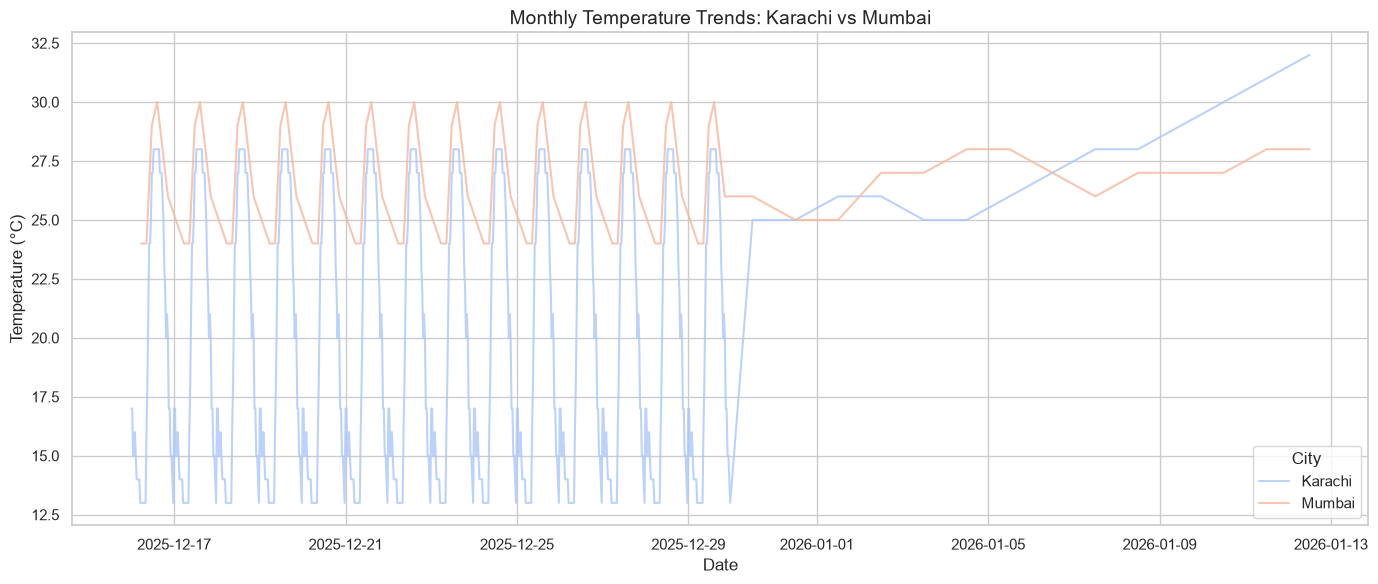

In [5]:
plt.figure(figsize=(14, 6))
sns.lineplot(data=df, x='Date & Time', y='Temperature (°C)', hue='City', palette='coolwarm', alpha=0.8)

plt.title('Monthly Temperature Trends: Karachi vs Mumbai', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.legend(title='City')

plt.tight_layout()
plt.savefig('visualizations/Temperature_Time_Series_Monthly.png')
plt.show()

**Analysis - Monthly Temperature Trend:**
- **Karachi (Blue):** Exhibits an aggressive sawtooth pattern with a wide diurnal range in historical observations (13°C at night up to 28°C during the day), followed by forecasted midday highs climbing to 32°C in January.
- **Mumbai (Orange):** Maintains a steady tropical coastal band throughout the window, buffering temperatures tightly between 24°C and 30°C.

### 4.3 Hourly Temperature Cycle

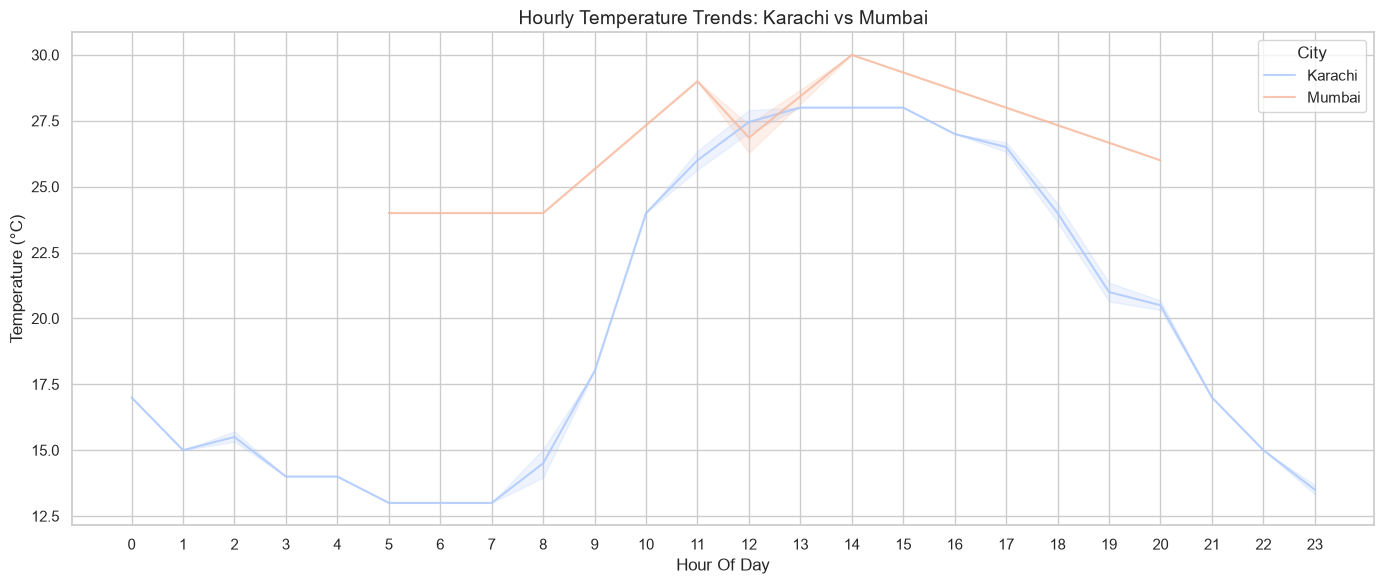

In [6]:
plt.figure(figsize=(14, 6))
sns.lineplot(data=df, x='Hour', y='Temperature (°C)', hue='City', palette='coolwarm', alpha=0.8)
plt.title('Hourly Temperature Trends: Karachi vs Mumbai', fontsize=14)
plt.xlabel('Hour Of Day')
plt.ylabel('Temperature (°C)')
plt.legend(title='City')
plt.xticks(range(24))
plt.tight_layout()
plt.savefig('visualizations/Temperature_Time_Series_Hourly.png')
plt.show()

**Analysis - Hourly Temperature Cycle:**
- **Overall Warmer Profile:** Mumbai (mean 26.84°C) remains warmer than Karachi (mean 19.90°C) across most hours of the day.
- **Nighttime Cooling:** Karachi's half-hourly records capture steep overnight cooling from 17°C at 00:00 down to 13°C between 05:00 and 07:00, while Mumbai's daytime-to-evening observations (05:30–20:30) stay at or above 24°C.
- **Afternoon Peak:** Both cities reach peak warmth around midday to early afternoon (12:00–15:00), with Karachi spanning a much wider day-to-night temperature swing.

### 4.4 Daily Average Temperature Trend

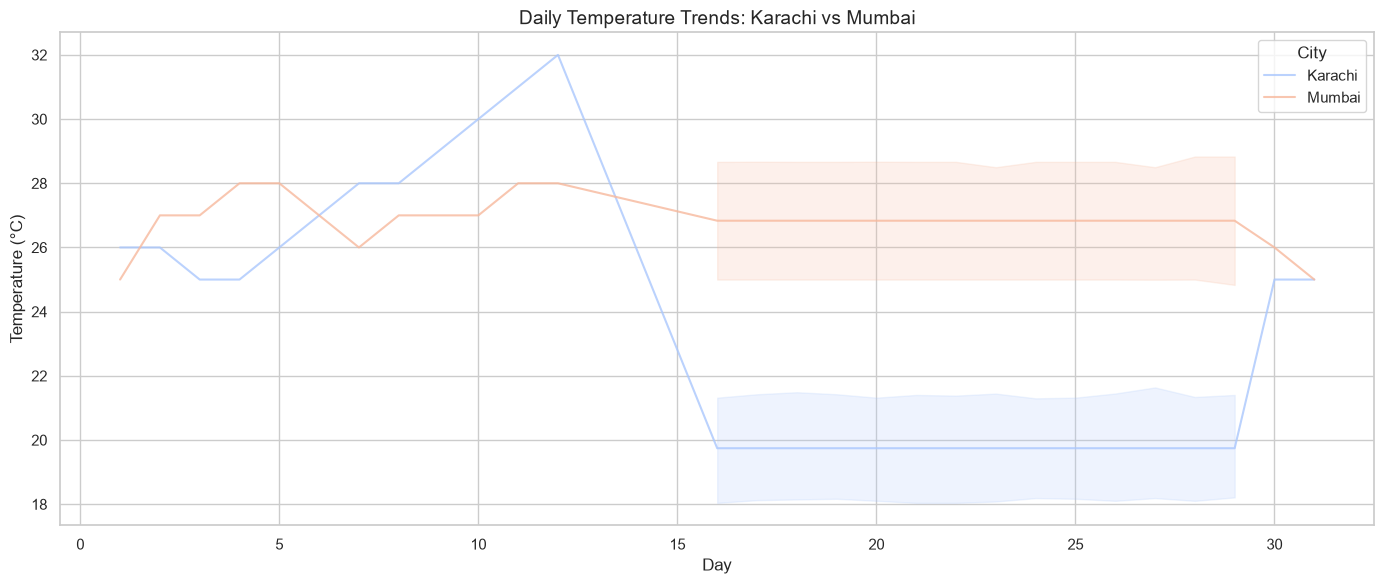

In [7]:
plt.figure(figsize=(14, 6))
sns.lineplot(data=df, x='Day', y='Temperature (°C)', hue='City', palette='coolwarm', alpha=0.8)
plt.title('Daily Temperature Trends: Karachi vs Mumbai', fontsize=14)
plt.xlabel('Day')
plt.ylabel('Temperature (°C)')
plt.legend(title='City')
plt.tight_layout()
plt.savefig('visualizations/Temperature_Time_Series_Daily.png')
plt.show()

**Analysis - Daily Temperature Trend:**
- **Forecast Smoothing:** Forecast records show smoother daily transitions compared to observed hourly variations.
- **Seasonal Contrast:** Karachi's daily mean remains consistently lower than Mumbai's, reflecting a cooler winter regime versus Mumbai's tropical baseline.

### 4.5 Temperature Distribution

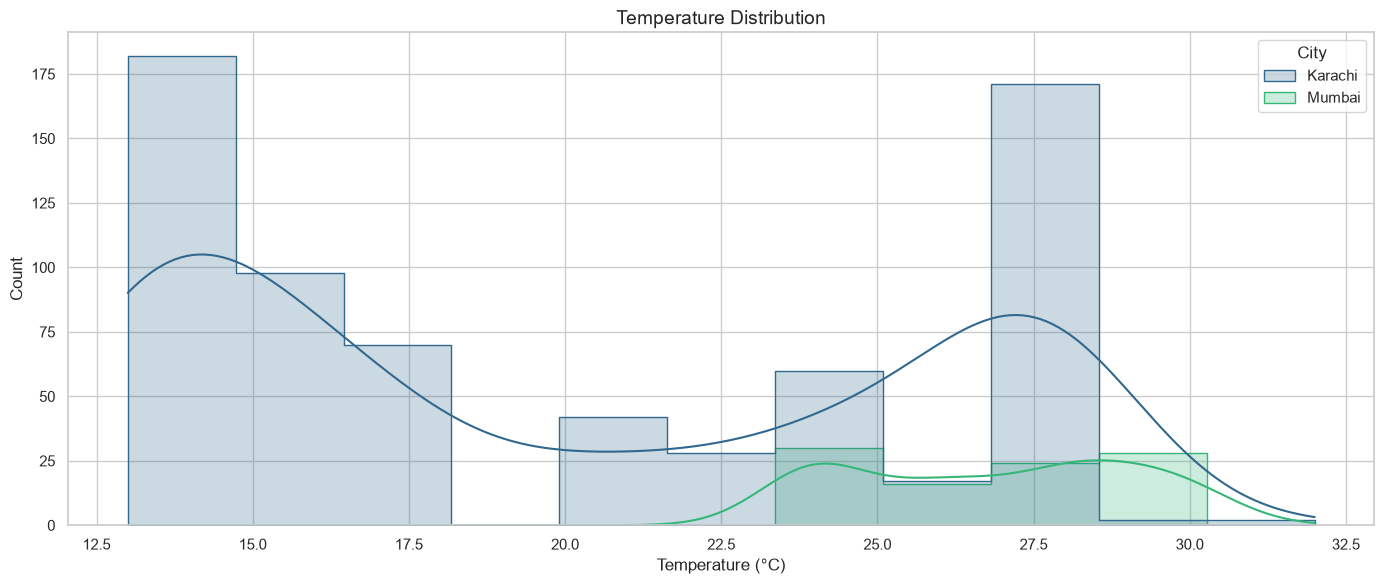

In [8]:
plt.figure(figsize=(14, 6))
sns.histplot(data=df, x='Temperature (°C)', hue='City', kde=True, element='step', palette='viridis')
plt.title('Temperature Distribution', fontsize=14)
plt.xlabel('Temperature (°C)')
plt.tight_layout()
plt.savefig('visualizations/Temperature_Distribution.png')
plt.show()

**Analysis - Temperature Distribution:**
- **Karachi:** Wide, bimodal spread spanning 13°C overnight minimums up to 28°C historical highs (and up to 32°C in 14-day midday forecasts).
- **Mumbai:** Narrow, peaked distribution concentrated tightly between 24°C and 30°C (std 2.21°C vs. Karachi's 5.87°C).

### 4.6 Humidity Distribution

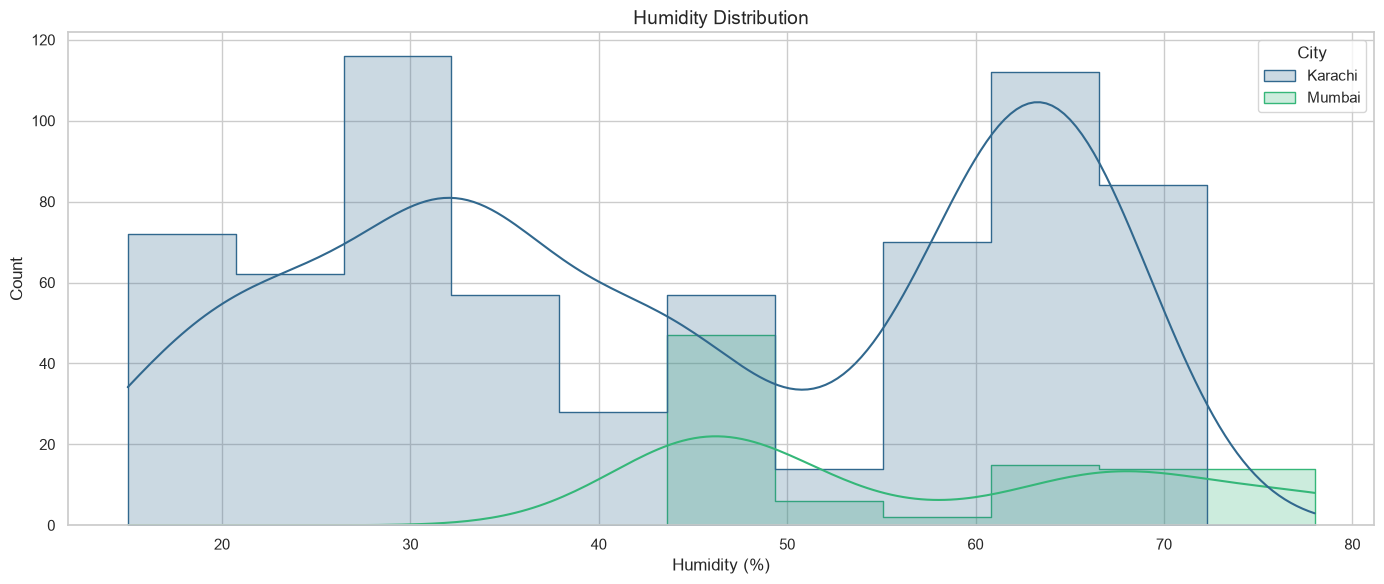

In [9]:
plt.figure(figsize=(14, 6))
sns.histplot(data=df, x='Humidity (%)', hue='City', kde=True, element='step', palette='viridis')
plt.title('Humidity Distribution', fontsize=14)
plt.xlabel('Humidity (%)')
plt.tight_layout()
plt.savefig('visualizations/Humidity_Distribution.png')
plt.show()

**Analysis - Humidity Distribution:**
- **Mumbai:** Sustains higher relative humidity overall (mean 57.38%, median 51.50%, range 44%–78%), peaking above 70% during early morning hours.
- **Karachi:** Exhibits lower, broader relative humidity (mean 44.09%, median 44.00%, range 15%–67%), with daytime readings frequently falling into the 20%–50% range under dry continental winter air.

### 4.7 Wind Speed & Atmospheric Pressure Comparison

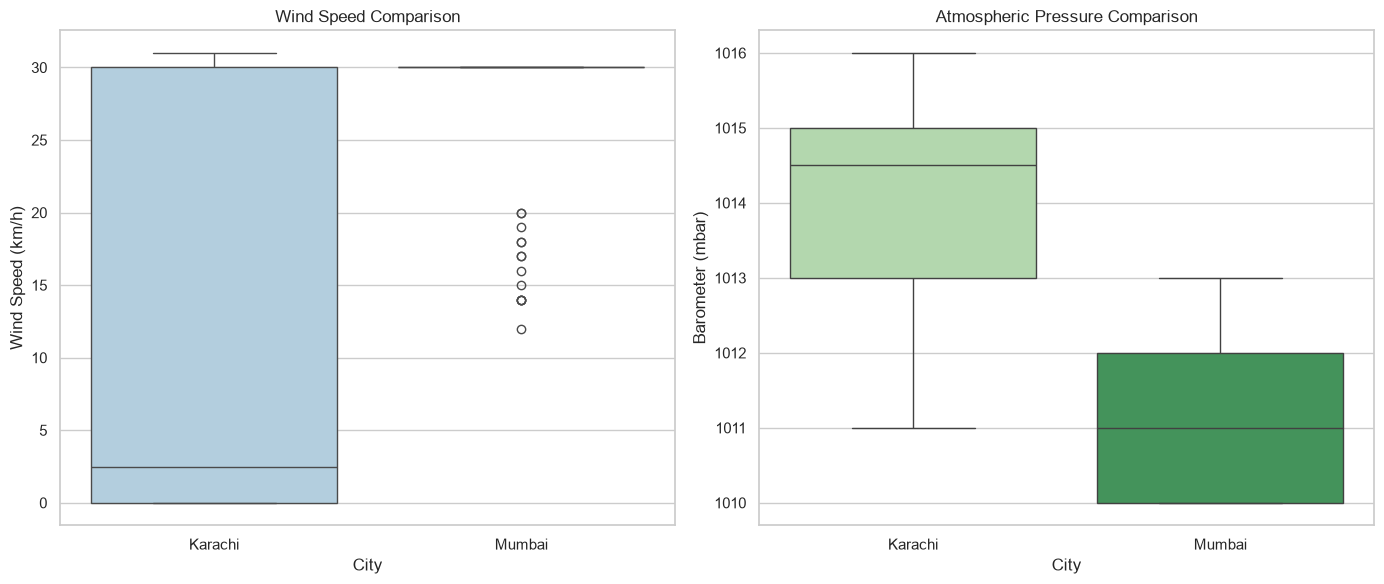

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='vert: bool was deprecated')
    sns.boxplot(data=df, x='City', y='Wind Speed (km/h)', ax=axes[0], hue='City', legend=False, palette='Blues')
    axes[0].set_title('Wind Speed Comparison')

    sns.boxplot(data=df, x='City', y='Barometer (mbar)', ax=axes[1], hue='City', legend=False, palette='Greens')
    axes[1].set_title('Atmospheric Pressure Comparison')

plt.tight_layout()
plt.savefig('visualizations/Wind_Pressure_Comparison.png')
plt.show()

**Analysis - Wind & Pressure Dynamics:**
- **Atmospheric Pressure:** Cooler, denser winter air produces consistently higher barometric readings in Karachi (1011–1016 mbar, mean 1014.23 mbar) than in Mumbai (1010–1013 mbar, mean 1011.29 mbar).
- **Wind Speed:** Mumbai records consistently brisker winds across the dataset (mean 28.04 km/h, median 30.00 km/h), whereas Karachi alternates between calm overnight conditions (0 km/h) and 30 km/h daytime breezes (mean 14.66 km/h, median 2.50 km/h).

## 5. Key Analytical Insights

In [11]:
def center_align(frame: pd.DataFrame):
    return frame.style.set_properties(**{'text-align': 'center'}).set_table_styles(
        [{'selector': 'th', 'props': [('text-align', 'center')]}]
    )


# 1. Early Morning Humidity (5 AM - 8 AM)
morning_mask = (df['Hour'] >= 5) & (df['Hour'] <= 8)
morning_stats = df.loc[morning_mask].groupby('City')['Humidity (%)'].mean().round(1).to_frame()

display(Markdown('### 5.1 Average Early Morning Humidity (5 AM - 8 AM)'))
display(Markdown('- **Observation:** Mumbai retains substantially higher morning moisture than Karachi, producing hazier mornings compared to Karachi\'s crisp, drier air.'))
display(center_align(morning_stats))

# 2. Midday Temperature & Pressure (12 PM - 2 PM)
noon_mask = (df['Hour'] >= 12) & (df['Hour'] <= 14)
noon_stats = df.loc[noon_mask].groupby('City')[['Temperature (°C)', 'Barometer (mbar)']].mean().round(1)

k_temp = noon_stats.loc['Karachi', 'Temperature (°C)'] if 'Karachi' in noon_stats.index else 'N/A'
k_pres = noon_stats.loc['Karachi', 'Barometer (mbar)'] if 'Karachi' in noon_stats.index else 'N/A'
m_temp = noon_stats.loc['Mumbai', 'Temperature (°C)'] if 'Mumbai' in noon_stats.index else 'N/A'
m_pres = noon_stats.loc['Mumbai', 'Barometer (mbar)'] if 'Mumbai' in noon_stats.index else 'N/A'

display(Markdown(
    f"### 5.2 Average Midday Temperature & Pressure (12 PM - 2 PM)\n"
    f"- **Temperature:** Mumbai ({m_temp}°C) averages warmer at midday than Karachi ({k_temp}°C).\n"
    f"- **Pressure:** Karachi ({k_pres} mbar) records higher atmospheric pressure than Mumbai ({m_pres} mbar)."
))
display(center_align(noon_stats))

# 3. Rainfall Events
df['Raining'] = df['Weather'].str.contains('rain|drizzle|shower|thunder', case=False, na=False)
rain_count = df.loc[df['Raining']].groupby('City').agg(Count=('Date & Time', 'count'))

display(Markdown('### 5.3 Total Rainfall Events'))
if rain_count.empty:
    display(Markdown('- **Observation:** No rain events recorded in either city across the observation window.'))
else:
    mumbai_rain = rain_count.loc['Mumbai', 'Count'] if 'Mumbai' in rain_count.index else 0
    karachi_rain = rain_count.loc['Karachi', 'Count'] if 'Karachi' in rain_count.index else 0
    display(Markdown(
        f"- **Mumbai:** {mumbai_rain} recorded rain hours.\n"
        f"- **Karachi:** {karachi_rain} recorded rain hours."
    ))
    display(center_align(rain_count))

### 5.1 Average Early Morning Humidity (5 AM - 8 AM)

- **Observation:** Mumbai retains substantially higher morning moisture than Karachi, producing hazier mornings compared to Karachi's crisp, drier air.

,Humidity (%)
City,
Karachi,65.500000
Mumbai,72.000000


### 5.2 Average Midday Temperature & Pressure (12 PM - 2 PM)
- **Temperature:** Mumbai (28.4°C) averages warmer at midday than Karachi (27.8°C).
- **Pressure:** Karachi (1013.3 mbar) records higher atmospheric pressure than Mumbai (1010.5 mbar).

,Temperature (°C),Barometer (mbar)
City,,
Karachi,27.800000,1013.300000
Mumbai,28.400000,1010.500000


### 5.3 Total Rainfall Events

- **Observation:** No rain events recorded in either city across the observation window.